# 02 - Time-based split and baseline

**Goal:** build the evaluation protocol (time-based split), train the first baseline model (logistic regression), and measure how much a random split would overestimate performance.

**Rules**
- The split is defined once in `src/data/split.py` and reused by every notebook.
- The test year (2017) and the late-check years (2018-2019) are not touched in this notebook. Models are developed on the validation year (2016) only.


## 0. Setup

Make the project folder importable and load the helpers from `src/data/split.py`.

In [1]:
import sys
sys.path.append("..")

import pandas as pd
from src.data.split import load_data, time_split, FEATURES, LABEL

## 1. Load the data and check the split

**Goal:** make sure the shared split code gives the same periods as the EDA notebook: sizes and label shares must match section 7 of `01_eda.ipynb`.

In [2]:
df = load_data()
train, validation, test, late = time_split(df)

for name, part in [("train", train), ("validation", validation), ("test", test), ("late check", late)]:
    print(name, len(part), round(part[LABEL].mean(), 3))

print(len(train) + len(validation) + len(test) + len(late) == len(df))

train 65957 0.293
validation 10606 0.291
test 10187 0.272
late check 19924 0.153
True


## 2. Baseline: logistic regression

**Goal:** train the simplest reasonable model and record its scores on the validation year (2016). Every later model has to beat this baseline.

**Preprocessing (decided in the EDA notebook):** `log1p` on the 11 skewed features, then standardization of all features. It is part of the pipeline, so it is learned on the training period only and then applied to validation without refitting.

**Class imbalance:** `class_weight="balanced"` gives more weight to the rare bug-inducing commits during training. The threshold stays at 0.5 for now; tuning it on validation comes in the next notebook.

**Metrics:** ROC-AUC (0.5 = chance), PR-AUC (chance = bug share, about 0.29), precision, recall, F1 and MCC (0 = chance). As a reference, the trivial model "everything is risky" is shown next to the baseline.

In [3]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

from src.evaluation.metrics import evaluate

log_features = [f for f in FEATURES if f != "ent"]

preprocess = ColumnTransformer([
    ("log_and_scale", Pipeline(
        [("log", FunctionTransformer(np.log1p)),
        ("scale", StandardScaler())]), log_features),
    ("scale_only", StandardScaler(), ["ent"]),
])

baseline = Pipeline([
    ("preprocess", preprocess),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000)),
])

In [4]:
baseline.fit(train[FEATURES], train[LABEL])

val_proba = baseline.predict_proba(validation[FEATURES])[:, 1]
trivial = np.ones(len(validation))

results = pd.DataFrame({
    "logistic regression": evaluate(validation[LABEL], val_proba),
    "always predict bug-inducing": evaluate(validation[LABEL], trivial),
})
results.round(3)

,logistic regression,always predict bug-inducing
ROC-AUC,0.784,0.500
PR-AUC,0.601,0.291
precision,0.474,0.291
recall,0.772,1.000
F1,0.587,0.451
MCC,0.382,0.000
bug share,0.291,0.291


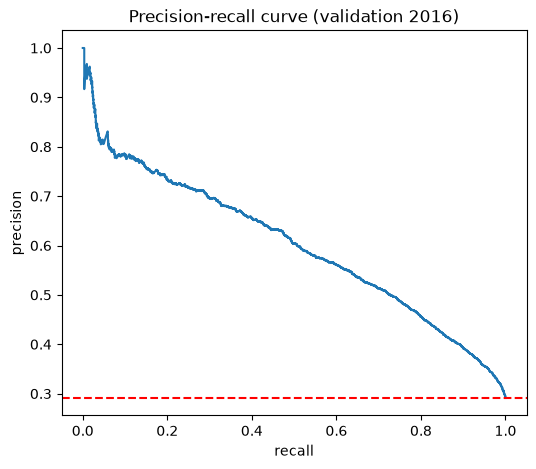

In [5]:
from sklearn.metrics import precision_recall_curve

precision, recall, _ = precision_recall_curve(validation[LABEL], val_proba)
curve = pd.DataFrame({"recall": recall, "precision": precision})

ax = curve.plot(x="recall", y="precision", figsize=(6, 5), title="Precision-recall curve (validation 2016)", legend=False)
ax.axhline(validation[LABEL].mean(), color="red", linestyle="--")
ax.set_ylabel("precision")
ax.figure.savefig("../reports/figures/02_baseline_pr_curve.png", dpi=150, bbox_inches="tight")

results.round(4).to_csv("../results/02_baseline_validation.csv")

**Observation**
- The baseline clearly beats chance on the validation year: ROC-AUC 0.784 (chance 0.5), PR-AUC 0.601 (chance 0.291, about twice as high), F1 0.587 (the trivial "everything is risky" model gets 0.451) and MCC 0.382 (chance 0). The scores are modest, as expected from the weak single-feature signals seen in the EDA.
- At the default threshold of 0.5 the model finds 77% of bug-inducing commits (recall 0.772), but only 47% of the commits it flags are really bug-inducing (precision 0.474). This means it flags about 47% of all commits as risky (recall x bug share / precision), which is too many to be useful for a developer. Threshold tuning and effort-aware metrics come in the model comparison notebook.
- The precision-recall curve stays above the chance line everywhere. The highest-scored commits are mostly truly bug-inducing (precision about 0.8 at 10% recall and about 0.7 at 30% recall), and precision falls towards the bug share as recall approaches 1.

**Decision:** use these validation scores as the baseline that Random Forest, XGBoost and LightGBM must beat. The test year (2017) is still untouched.

## 3. Time split vs random split

**Goal:** measure how much a random split would change the baseline scores. We take all commits from 2003-2016, pick 10,606 of them at random as a pseudo-validation set (the same size as the 2016 validation year) and train on the rest (65,957 commits, the same size as the time-split training set). This is repeated with 5 different random seeds and the scores are averaged. The test year (2017) is not used.

In [6]:
from sklearn.base import clone

dev = pd.concat([train, validation])

random_rows = []
for seed in range(5):
    rand_val = dev.sample(n=len(validation), random_state=seed)
    rand_train = dev.drop(rand_val.index)
    model = clone(baseline).fit(rand_train[FEATURES], rand_train[LABEL])
    proba = model.predict_proba(rand_val[FEATURES])[:, 1]
    random_rows.append(evaluate(rand_val[LABEL], proba))

random_mean = pd.DataFrame(random_rows).mean()
comparison = pd.DataFrame({
    "time split": results["logistic regression"],
    "random split": random_mean,
})
comparison["difference"] = comparison["random split"] - comparison["time split"]
comparison.round(3)

,time split,random split,difference
ROC-AUC,0.784,0.781,-0.002
PR-AUC,0.601,0.601,0.000
precision,0.474,0.498,0.024
recall,0.772,0.716,-0.056
F1,0.587,0.587,-0.000
MCC,0.382,0.387,0.005
bug share,0.291,0.290,-0.001


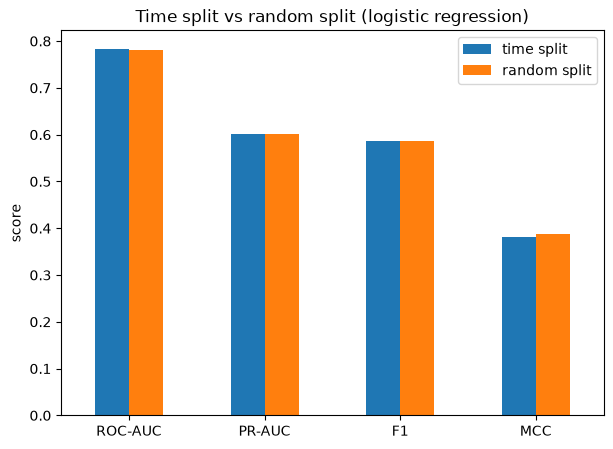

In [7]:
ax = comparison.loc[["ROC-AUC", "PR-AUC", "F1", "MCC"], ["time split", "random split"]].plot(
    kind="bar", figsize=(7, 5), title="Time split vs random split (logistic regression)", rot=0)
ax.set_ylabel("score")
ax.figure.savefig("../reports/figures/02_time_vs_random_split.png", dpi=150, bbox_inches="tight")
comparison.round(4).to_csv("../results/02_time_vs_random_split.csv")

**Observation**
- For logistic regression the random split does not overestimate performance: the threshold-free scores are practically identical (ROC-AUC 0.784 vs 0.781, PR-AUC 0.601 vs 0.601), and so are F1 (0.587 vs 0.587) and MCC (0.382 vs 0.387). The spread across the 5 random runs was not measured, so differences below about 0.01 are treated as no real difference.
- A simple linear model with 12 aggregate features probably cannot exploit period-specific patterns, which would explain why it gains nothing from seeing same-period commits during training. More flexible models may behave differently, so we repeat this check for them.
- At the fixed threshold of 0.5 the two splits trade precision and recall differently (precision 0.474 vs 0.498, recall 0.772 vs 0.716). The time-split model flags about 47% of the 2016 commits, the random-split model about 42%, although the true bug share is the same (29%). So the 2016 commits look somewhat riskier to a model trained on earlier years, a mild drift. This is a reason to tune the threshold on the most recent period.

**Decision:** keep the time split as the evaluation protocol (it matches real use, where the model predicts future commits), but report this result as it is: for the baseline the gap is negligible.

## Summary and decisions

- The time-based split is implemented in `src/data/split.py` (train 2003-2015, validation 2016, test 2017, late check 2018-2019) and reused by all notebooks. The test and late-check years are untouched.
- Baseline (logistic regression, validation 2016): ROC-AUC 0.784, PR-AUC 0.601, F1 0.587, MCC 0.382. Clearly above chance, but modest.
- At threshold 0.5 the baseline flags about 47% of commits; threshold tuning on validation and effort-aware metrics come next.
- For this simple model a random split gives almost the same scores as the time split. We keep the time split as the protocol and repeat the comparison for the more flexible models.

**Next:** `03_model_comparison.ipynb` - Random Forest, XGBoost and LightGBM, imbalance handling, threshold tuning and effort-aware metrics.